In [1]:
modules = ["pandas","missingno", "seaborn", "matplotlib"]

import sys
import os.path
from subprocess import check_call
import importlib
import os

def instala(modules):
  print("Instalando módulos")
  for m in modules:
      # para el import quitamos [...] y ==...
      p = m.find("[")
      mi = m if p==-1 else m[:p]
      p = mi.find("==")
      mi = mi if p==-1 else mi[:p]

      torch_loader = importlib.util.find_spec(mi)
      if torch_loader is not None:
          print(m," encontrado")
      else:
          print(m," No encontrado, instalando...",end="")  
          try:        
            r = check_call([sys.executable, "-m", "pip", "install", "--user", m])
            print("¡hecho!")
          except:
            print("¡Problema al instalar ",m,"! ¿seguro que el módulo existe?",sep="")
              
  print("¡Terminado!")

instala(modules)

Instalando módulos
pandas  encontrado
missingno  encontrado
seaborn  encontrado
matplotlib  encontrado
¡Terminado!


In [2]:
import pandas as pd
import numpy as np
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt

In [17]:
path = r'../../data/limpio_merged_data.csv'
df = pd.read_csv(path, header=0)
df

,timestamp,open_bitget,high_bitget,low_bitget,close_bitget,volumen_bitget,var_diaria_bitget,volatilidad_50_bitget,volatilidad_200_bitget,rango_dia_bitget,...,mDvolatilidad_50_mDderibit,mDvolatilidad_200_mDderibit,mDrango_dia_mDderibit,mDmomentum_50_mDderibit,mDmomentum_200_mDderibit,mDSMA_50_mDderibit,mDSMA_200_mDderibit,mDEMA_50_mDderibit,mDEMA_200_mDderibit,mD_RSI_mDderibit
0,2022-03-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2022-03-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2022-03-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2022-03-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2022-03-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1093,2025-02-28,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1094,2025-03-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1095,2025-03-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1096,2025-03-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 1. Descripción general

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1098 entries, 0 to 1097
Data columns (total 85 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   timestamp                    1098 non-null   object 
 1   open_bitget                  365 non-null    float64
 2   high_bitget                  365 non-null    float64
 3   low_bitget                   365 non-null    float64
 4   close_bitget                 365 non-null    float64
 5   volumen_bitget               365 non-null    float64
 6   var_diaria_bitget            364 non-null    float64
 7   volatilidad_50_bitget        316 non-null    float64
 8   volatilidad_200_bitget       166 non-null    float64
 9   rango_dia_bitget             365 non-null    float64
 10  momentum_50_bitget           315 non-null    float64
 11  momentum_200_bitget          165 non-null    float64
 12  SMA_50_bitget                316 non-null    float64
 13  SMA_200_bitget    

In [14]:
df.describe()

,open_bitget,high_bitget,low_bitget,close_bitget,volumen_bitget,var_diaria_bitget,volatilidad_50_bitget,volatilidad_200_bitget,rango_dia_bitget,momentum_50_bitget,...,mDvolatilidad_50_mDderibit,mDvolatilidad_200_mDderibit,mDrango_dia_mDderibit,mDmomentum_50_mDderibit,mDmomentum_200_mDderibit,mDSMA_50_mDderibit,mDSMA_200_mDderibit,mDEMA_50_mDderibit,mDEMA_200_mDderibit,mD_RSI_mDderibit
count,365.000000,365.000000,365.000000,365.000000,3.650000e+02,364.000000,316.000000,166.000000,365.000000,315.000000,...,317.000000,167.000000,366.000000,316.000000,166.000000,317.000000,167.000000,366.000000,366.000000,353.000000
mean,70500.966466,71927.825233,69065.149014,70588.603178,3.904518e+10,-0.083868,4385.889933,10158.124008,87.636712,-4732.506286,...,4717.406987,9626.346810,127.480874,5674.681962,18999.496988,71494.088328,67981.540838,69289.497754,63052.417187,53.749244
std,14947.742332,15187.763131,14673.942936,14931.750373,2.228896e+10,2.722757,2554.647299,5398.854543,1894.717068,11820.961606,...,2700.805502,5448.455157,1962.534439,12520.901171,17348.985595,13320.613132,5140.870014,13297.654802,8502.434343,16.314368
min,51364.930000,52211.400000,46768.330000,51364.610000,9.390000e+09,-10.829129,2422.235796,3798.180251,-5813.290000,-36406.640000,...,2538.657935,3993.076349,-6029.500000,-14103.500000,-8720.000000,59192.590000,63270.932500,49734.500000,49734.500000,13.569008
25%,59810.070000,60812.950000,58195.940000,59840.790000,2.484000e+10,-1.485424,3095.129573,4179.430972,-945.160000,-8257.875000,...,3261.005817,4402.740765,-898.375000,-3052.250000,571.250000,62520.380000,63717.267500,61573.331129,58313.679257,41.757540
50%,64189.730000,65199.870000,62956.280000,64258.580000,3.320000e+10,-0.010456,3507.375476,10473.712623,21.270000,-1631.380000,...,3749.131052,7816.953231,37.250000,2360.750000,27166.500000,65626.850000,65373.160000,64258.442730,61236.866440,52.666974
75%,88950.040000,90616.000000,86995.030000,88953.940000,4.652000e+10,1.379436,3874.056963,15617.274534,976.820000,2959.960000,...,4272.777740,15428.983510,1020.000000,10322.500000,32317.375000,75695.950000,71758.415000,70116.300054,64123.173204,66.242938
max,101062.840000,103888.280000,100248.260000,101061.860000,1.420700e+11,9.102832,12085.230106,17140.097918,7835.860000,13291.380000,...,12702.641837,17931.071418,8348.500000,38261.000000,49559.000000,99318.380000,79413.602500,98911.269413,84608.488036,88.491359


## 2. Conteo de nulos

In [15]:
df.isnull().sum(axis=0)

timestamp                0
open_bitget            733
high_bitget            733
low_bitget             733
close_bitget           733
                      ... 
mDSMA_50_mDderibit     781
mDSMA_200_mDderibit    931
mDEMA_50_mDderibit     732
mDEMA_200_mDderibit    732
mD_RSI_mDderibit       745
Length: 85, dtype: int64

<Axes: >

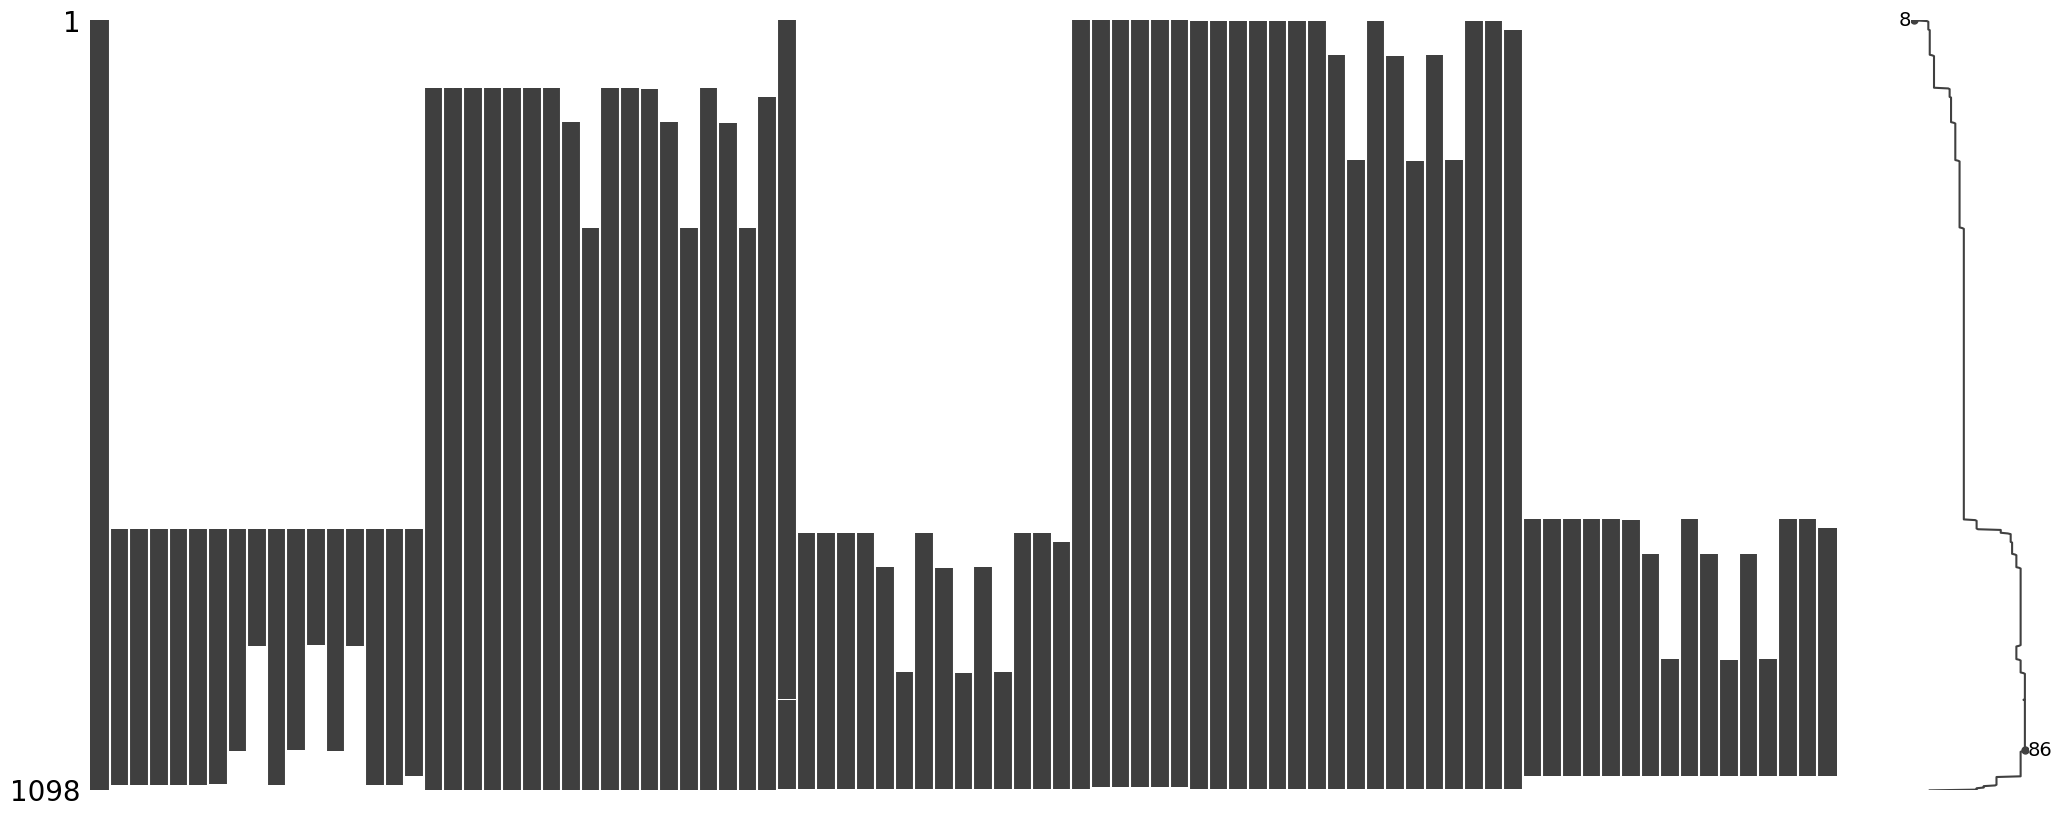

In [18]:
msno.matrix(df)

## 3. Correlaciones

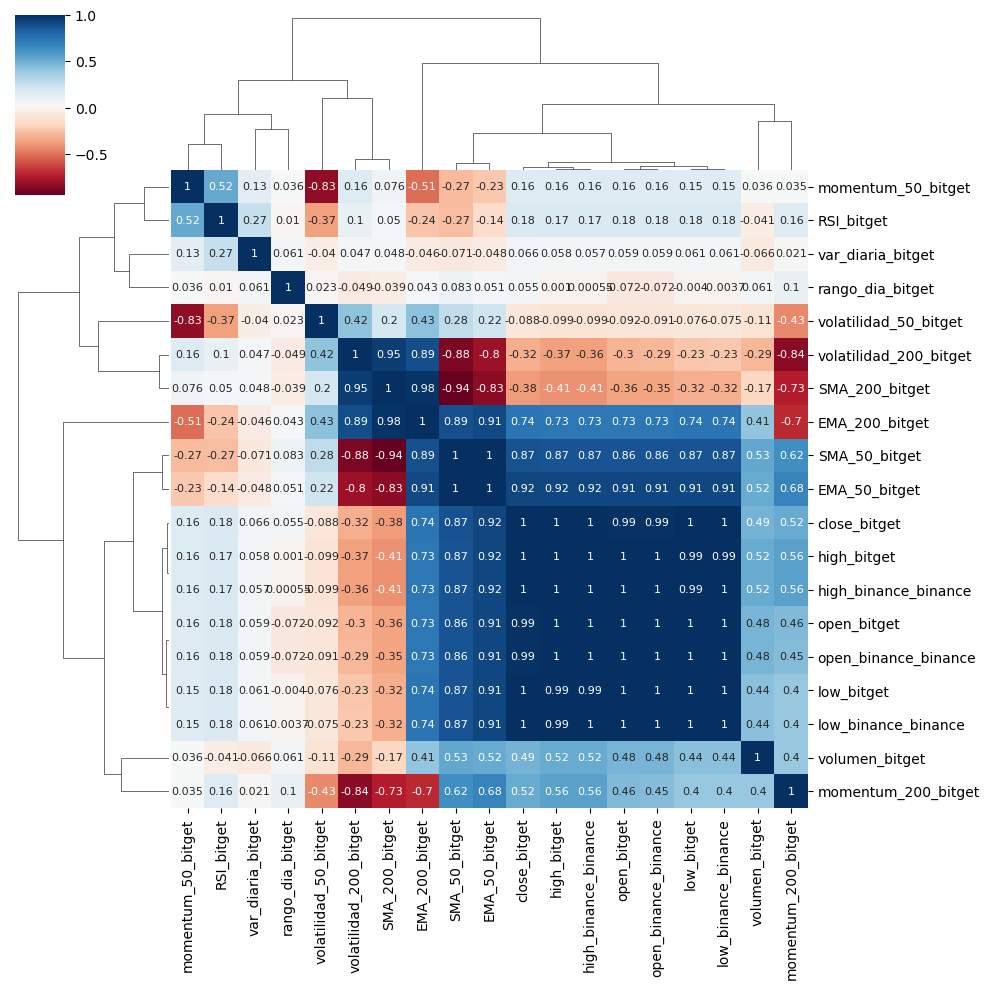

In [26]:
g = sns.clustermap(df.iloc[:, 1:20].corr(), 
                   method = 'complete', 
                   cmap   = 'RdBu', 
                   annot  = True, 
                   annot_kws = {'size': 8})